#### Oversampling
Using SMOTE


Creates synthetic samples specifically for the minority class, based on nearest neighbors. (Yes, KNN!) It's quite a useful way to synthesize data when you want to ensure the rarer combinations need representation.

In [2]:
# pip install imblearn
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# Loading the dataset
df = pd.read_csv("../../laptopprice_dataset_cleaned.csv")


df

,Ram,Weight,Price,TouchScreen,Ips,Ppi,HDD,SSD,Company_Acer,Company_Apple,...,Cpu_brand_Intel Core i3,Cpu_brand_Intel Core i5,Cpu_brand_Intel Core i7,Cpu_brand_Other Intel Processor,Gpu_brand_AMD,Gpu_brand_Intel,Gpu_brand_Nvidia,Os_Mac,Os_Others,Os_Windows
0,8,1.37,11.175755,0,1,226.983005,0,128,0,1,...,0,1,0,0,0,1,0,1,0,0
1,8,1.34,10.776777,0,0,127.677940,0,0,0,1,...,0,1,0,0,0,1,0,1,0,0
2,8,1.86,10.329931,0,0,141.211998,0,256,0,0,...,0,1,0,0,0,1,0,0,1,0
3,16,1.83,11.814476,0,1,220.534624,0,512,0,1,...,0,0,1,0,1,0,0,1,0,0
4,8,1.37,11.473101,0,1,226.983005,0,256,0,1,...,0,1,0,0,0,1,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1268,4,2.20,10.555257,0,0,100.454670,500,0,0,0,...,0,0,1,0,0,0,1,0,0,1
1269,4,1.80,10.433899,1,1,157.350512,0,128,0,0,...,0,0,1,0,0,1,0,0,0,1
1270,16,1.30,11.288115,1,1,276.053530,0,512,0,0,...,0,0,1,0,0,1,0,0,0,1
1271,2,1.50,9.409283,0,0,111.935204,0,0,0,0,...,0,0,0,1,0,1,0,0,0,1


In [3]:
# remove NaNs
df = df.dropna()

#### The problem

<Axes: xlabel='TouchScreen', ylabel='Count'>

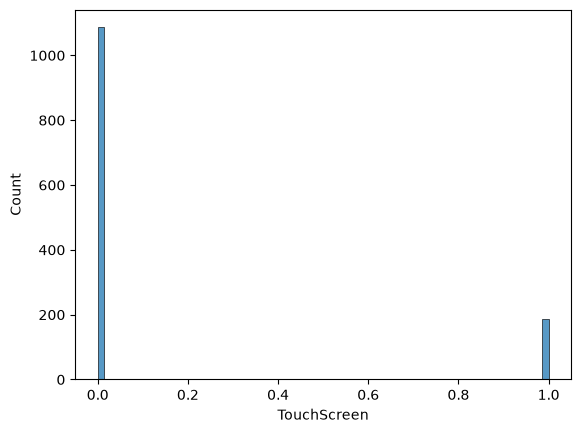

In [6]:

sns.histplot(df, x="TouchScreen")

# The number of pools we have is massively underrepresented!
# And assume that we cannot collect any more data than this. 

# We have to create some data in order to represent the values better.

In [7]:
df['TouchScreen'].value_counts()

TouchScreen
0    1086
1     187
Name: count, dtype: int64

#### SMOTE

In [8]:

df.shape

(1273, 44)

In [9]:
# Another x y split to prevent a data leakage
X = df.drop(columns="TouchScreen", axis=1)
y = df['TouchScreen']

<Axes: xlabel='TouchScreen', ylabel='Count'>

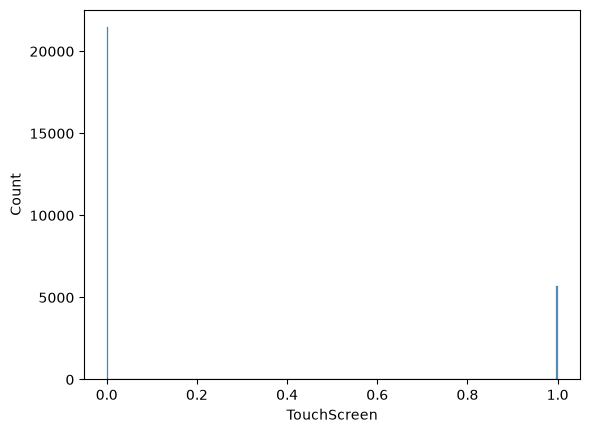

In [13]:
from imblearn.over_sampling import SMOTE

strategy = {
    0: 21450,
    1: 5713
}

smote = SMOTE(sampling_strategy=strategy)

X_resampled, y_resampled = smote.fit_resample(X, y)

# reconstruct the dataframe
df_oversampled_smote = pd.DataFrame(X_resampled)
df_oversampled_smote["TouchScreen"] = y_resampled

sns.histplot(df_oversampled_smote, x="TouchScreen")

In [11]:
df_oversampled_smote.shape

(27163, 44)

In [14]:
df_oversampled_smote['TouchScreen'].value_counts()

TouchScreen
0    21450
1     5713
Name: count, dtype: int64

In [15]:
# switching to decimal notation for the variance checks
pd.set_option('display.float_format', lambda x: "%.2f" % x)

In [16]:

df.describe()

,Ram,Weight,Price,TouchScreen,Ips,Ppi,HDD,SSD,Company_Acer,Company_Apple,...,Cpu_brand_Intel Core i3,Cpu_brand_Intel Core i5,Cpu_brand_Intel Core i7,Cpu_brand_Other Intel Processor,Gpu_brand_AMD,Gpu_brand_Intel,Gpu_brand_Nvidia,Os_Mac,Os_Others,Os_Windows
count,1273.00,1273.00,1273.00,1273.00,1273.00,1273.00,1273.00,1273.00,1273.00,1273.00,...,1273.00,1273.00,1273.00,1273.00,1273.00,1273.00,1273.00,1273.00,1273.00,1273.00
mean,8.45,2.04,10.83,0.15,0.28,146.95,413.72,186.25,0.08,0.02,...,0.11,0.33,0.40,0.11,0.14,0.55,0.31,0.02,0.12,0.86
std,5.10,0.67,0.62,0.35,0.45,42.93,518.05,186.53,0.27,0.13,...,0.31,0.47,0.49,0.31,0.34,0.50,0.46,0.13,0.32,0.34
min,2.00,0.69,9.13,0.00,0.00,90.58,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,4.00,1.50,10.39,0.00,0.00,127.34,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00
50%,8.00,2.04,10.87,0.00,0.00,141.21,0.00,256.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,1.00
75%,8.00,2.31,11.29,0.00,1.00,157.35,1000.00,256.00,0.00,0.00,...,0.00,1.00,1.00,0.00,0.00,1.00,1.00,0.00,0.00,1.00
max,64.00,4.70,12.69,1.00,1.00,352.47,2000.00,1024.00,1.00,1.00,...,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00


In [17]:
df_oversampled_smote.describe()

,Ram,Weight,Price,Ips,Ppi,HDD,SSD,Company_Acer,Company_Apple,Company_Asus,...,Cpu_brand_Intel Core i5,Cpu_brand_Intel Core i7,Cpu_brand_Other Intel Processor,Gpu_brand_AMD,Gpu_brand_Intel,Gpu_brand_Nvidia,Os_Mac,Os_Others,Os_Windows,TouchScreen
count,27163.00,27163.00,27163.00,27163.00,27163.00,27163.00,27163.00,27163.00,27163.00,27163.00,...,27163.00,27163.00,27163.00,27163.00,27163.00,27163.00,27163.00,27163.00,27163.00,27163.00
mean,8.35,2.00,10.84,0.17,149.90,393.49,192.81,0.03,0.01,0.05,...,0.24,0.34,0.08,0.08,0.52,0.23,0.01,0.06,0.83,0.21
std,4.67,0.64,0.60,0.38,44.73,512.57,189.81,0.17,0.11,0.21,...,0.43,0.47,0.28,0.26,0.50,0.42,0.11,0.24,0.37,0.41
min,2.00,0.69,9.13,0.00,90.58,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,4.00,1.48,10.42,0.00,127.34,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00
50%,8.00,2.03,10.89,0.00,141.21,0.00,256.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,1.00,0.00
75%,8.00,2.28,11.30,0.00,157.35,1000.00,256.00,0.00,0.00,0.00,...,0.00,1.00,0.00,0.00,1.00,0.00,0.00,0.00,1.00,0.00
max,64.00,4.70,12.69,1.00,352.47,2000.00,1024.00,1.00,1.00,1.00,...,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00


In [18]:
df.var(numeric_only=True)

Ram                                   26.00
Weight                                 0.45
Price                                  0.38
TouchScreen                            0.13
Ips                                    0.20
Ppi                                 1842.71
HDD                               268380.45
SSD                                34794.03
Company_Acer                           0.07
Company_Apple                          0.02
Company_Asus                           0.10
Company_Chuwi                          0.00
Company_Dell                           0.18
Company_Fujitsu                        0.00
Company_Google                         0.00
Company_HP                             0.17
Company_Huawei                         0.00
Company_LG                             0.00
Company_Lenovo                         0.18
Company_MSI                            0.04
Company_Mediacom                       0.01
Company_Microsoft                      0.00
Company_Razer                   

In [19]:
df_oversampled_smote.var(numeric_only=True)

Ram                                   21.76
Weight                                 0.40
Price                                  0.36
Ips                                    0.14
Ppi                                 2000.95
HDD                               262724.37
SSD                                36027.61
Company_Acer                           0.03
Company_Apple                          0.01
Company_Asus                           0.04
Company_Chuwi                          0.00
Company_Dell                           0.13
Company_Fujitsu                        0.00
Company_Google                         0.00
Company_HP                             0.10
Company_Huawei                         0.00
Company_LG                             0.00
Company_Lenovo                         0.11
Company_MSI                            0.03
Company_Mediacom                       0.00
Company_Microsoft                      0.00
Company_Razer                          0.00
Company_Samsung                 

<Axes: >

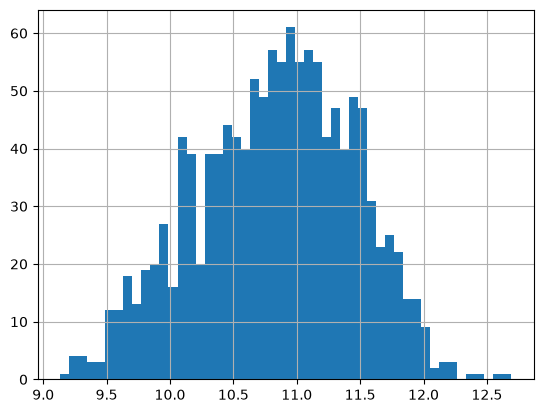

In [20]:
df['Price'].hist(bins=50)

<Axes: >

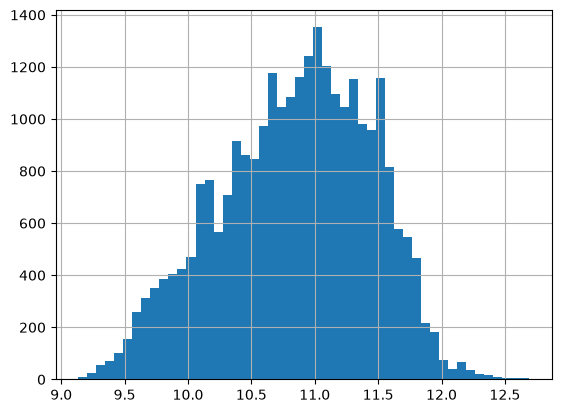

In [21]:
df_oversampled_smote['Price'].hist(bins=50)

In [22]:
# to be added later => extract only the synthetic ones from the oversampled df
# so we can actually study the synthesized houses here

# got this from AI / ChatGPT
diff = (
    df_oversampled_smote.merge(df.drop_duplicates(), how="left", indicator=True)
       .query('_merge == "left_only"')
       .drop(columns="_merge")
)

# these are the synthetic ones only
# SMOTE also falls for the trap => renovations in the past, built the house in future
diff

,Ram,Weight,Price,Ips,Ppi,HDD,SSD,Company_Acer,Company_Apple,Company_Asus,...,Cpu_brand_Intel Core i5,Cpu_brand_Intel Core i7,Cpu_brand_Other Intel Processor,Gpu_brand_AMD,Gpu_brand_Intel,Gpu_brand_Nvidia,Os_Mac,Os_Others,Os_Windows,TouchScreen
1273,7,1.14,10.96,1,165.63,0,256,0,0,0,...,1,0,0,0,1,0,0,0,1,0
1274,7,1.33,10.97,0,128.23,0,0,0,1,0,...,1,0,0,0,1,0,1,0,0,0
1275,4,1.63,9.69,0,111.94,0,0,0,0,0,...,0,0,1,0,1,0,0,0,1,0
1276,4,1.98,10.19,0,100.45,1000,0,0,0,0,...,1,0,0,0,1,0,0,1,0,0
1277,4,1.86,9.57,0,100.45,500,0,0,0,0,...,0,0,0,0,1,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27158,11,2.03,11.27,0,141.21,0,512,0,0,0,...,0,1,0,0,0,0,0,0,1,1
27159,8,1.25,11.48,0,200.84,0,256,0,0,0,...,0,1,0,0,1,0,0,0,1,1
27160,30,1.06,11.86,0,165.63,0,512,0,0,0,...,0,1,0,0,1,0,0,0,1,1
27161,16,1.28,11.78,0,252.23,0,1000,0,0,0,...,0,1,0,0,1,0,0,0,1,1
